Radon transform 

- data
  - generate ellipse phantoms
  - run skimage forward Radon
  - add noise, store coefficients
  - So each data point has three components: (Original, Noised Sinogram, Noise coefficients)
- Invert with chosen kernel, evaluate MSE
- (...do numerical analysis)

In [1]:
import numpy as np
import matplotlib.pyplot as plt


import implementation.filter
from implementation.transform import iRadon


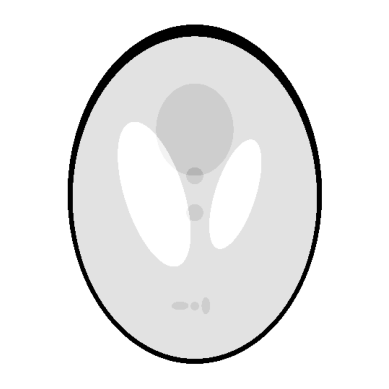

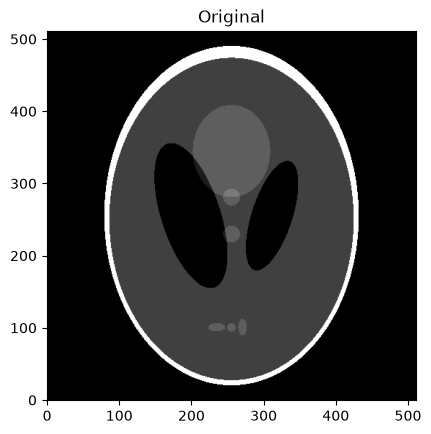

In [2]:
#Generating phantoms

from implementation.phantomgen import phantom

#will do later

image1 = phantom

plt.imshow(image1, cmap=plt.cm.Greys_r, origin='lower')
plt.title("Original")
plt.show()






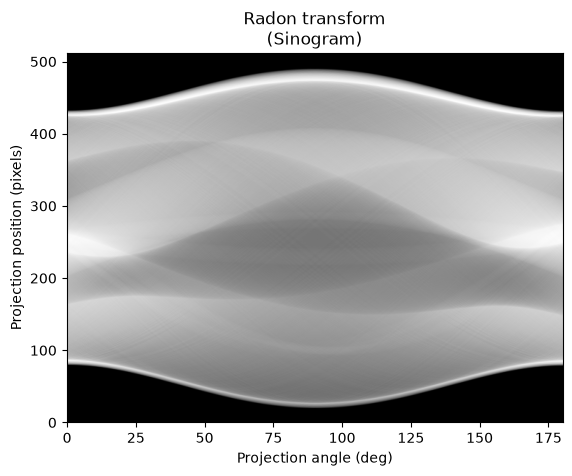

In [3]:
#generate sinogram using skimage radon 

from skimage.transform import radon

theta = np.linspace(0.0, 180.0, max(image1.shape), endpoint=False)
sinogram1 = radon(image1, theta=theta)
dx, dy = 0.5 * 180.0 / max(image1.shape), 0.5 / sinogram1.shape[0]
plt.title("Radon transform\n(Sinogram)")
plt.xlabel("Projection angle (deg)")
plt.ylabel("Projection position (pixels)")
plt.imshow(
    sinogram1,
    cmap=plt.cm.Greys_r,
    extent=(-dx, 180.0 + dx, -dy, sinogram1.shape[0] + dy),
    aspect='auto',
)

plt.show()

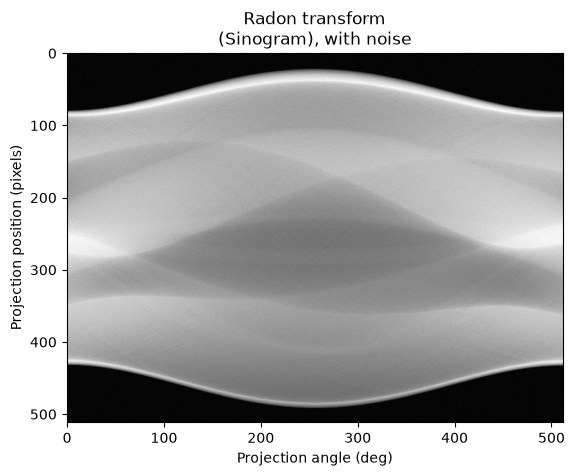

In [4]:
#noising 

from implementation.noise import both_noises

noised_sinogram1 = both_noises(sinogram1, I0=1e4, sigma=0.02, rng_p=0, rng_g=1)

plt.title("Radon transform\n(Sinogram), with noise")
plt.xlabel("Projection angle (deg)")
plt.ylabel("Projection position (pixels)")
plt.imshow(
    noised_sinogram1,
    cmap=plt.cm.Greys_r,
    aspect='auto',
)

plt.show()

FBP rms reconstruction error: 0.0484


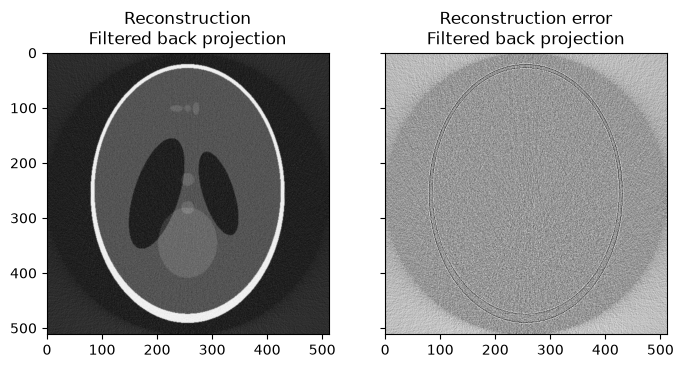

In [ ]:
# Reconstruction using filtered back projection

import implementation.filter as filt
from implementation.transform import iRadon


filter1 = filt.RampFilter

# Using our FBP implementation (once we get it working):
#reconstruction1 = iRadon(sinogram=noised_sinogram1, kernel=filter1, resolution=512)

# using Skimage iRadon, with ramm-lak filter, as a placeholder:
from skimage.transform import iradon
#reconstruction1 = iradon(noised_sinogram1, theta=theta, filter_name='ramp')
from implementation.transform import inverseRadon
reconstruction1 = inverseRadon(sinogram=noised_sinogram1, theta_deg=theta, kernel="ramp")


error1 = reconstruction1 - image1

print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error1**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nRamm-lak ramp filter")
ax1.imshow(reconstruction1, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nRamm-lak ramp filter")
ax2.imshow(error1, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()


FBP rms reconstruction error: 0.0469


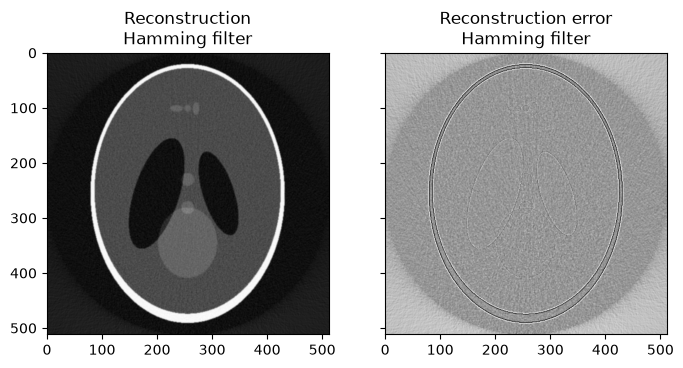

In [8]:
reconstruction1_1 = inverseRadon(sinogram=noised_sinogram1, theta_deg=theta, kernel="hamming")


error1_1 = reconstruction1_1 - image1

print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error1_1**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nHamming filter")
ax1.imshow(reconstruction1_1, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nHamming filter")
ax2.imshow(error1_1, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()

## Conclusion

After passing through with the plain ramm-lak ramp filter, we can see that the noise was amplified.

Using the Hamming filter, the noise in our reconstruction was ever-so-slightly decreased, and MSE went from 0.0484 to 0.0469